<a href="https://colab.research.google.com/github/MeouchyCharbel/Neural-Machine-Translation/blob/feature%2Ftransformer-evaluation/01_data_and_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import glob
import urllib.request
import zipfile

DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip"
ZIP_PATH = "fra-eng.zip"
EXTRACT_DIR = "data_raw"

urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as zip_file:
    zip_file.extractall(EXTRACT_DIR)

text_file = glob.glob(f"{EXTRACT_DIR}/**/fra.txt", recursive=True)[0]

print("Dataset file:", text_file)

Dataset file: data_raw/fra.txt


In [26]:
import csv
import pandas as pd

pairs = pd.read_csv(
    text_file,
    sep="\t",
    header=None,
    usecols=[0, 1],
    names=["en", "fr"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8"
)

print("Number of pairs:", len(pairs))
pairs.sample(5, random_state=42)

Number of pairs: 167130


,en,fr
59241,I think it's fascinating.,Je pense que c'est fascinant.
135841,Why don't we talk about something else?,Pourquoi ne parlons-nous pas d'autre chose ?
113994,I don't really know what you mean.,Je ne sais pas vraiment ce que tu veux dire.
138328,Those prisoners were set free yesterday.,Ces prisonnières ont été libérées hier.
31886,You're a funny girl.,T'es une drôle de fille.


In [27]:
rows_before = len(pairs)

pairs = pairs.dropna(subset=["en", "fr"]).copy()

pairs["en"] = pairs["en"].str.strip()
pairs["fr"] = pairs["fr"].str.strip()

pairs["en_words"] = pairs["en"].str.split().str.len()

pairs = pairs[(pairs["en"] != "") & (pairs["fr"] != "")]
pairs = pairs.drop_duplicates(subset=["en", "fr"])
pairs = pairs[pairs["en_words"] <= 15]

pairs = pairs.reset_index(drop=True)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(pairs))
print("Rows removed:", rows_before - len(pairs))
print("Unique English sentences:", pairs["en"].nunique())
print("Longest English sentence:", pairs["en_words"].max(), "words")

Rows before cleaning: 167130
Rows after cleaning: 166340
Rows removed: 790
Unique English sentences: 116198
Longest English sentence: 15 words


In [28]:
from sklearn.model_selection import train_test_split

unique_en = pairs["en"].drop_duplicates()

train_en, test_en = train_test_split(
    unique_en,
    test_size=1000,
    random_state=42
)

train_pairs = pairs[pairs["en"].isin(train_en)].reset_index(drop=True)

test_pairs = pairs[pairs["en"].isin(test_en)]
test_pairs = test_pairs.drop_duplicates(subset="en").reset_index(drop=True)

overlap = set(train_pairs["en"]) & set(test_pairs["en"])

print("Training pairs:", len(train_pairs))
print("Test pairs:", len(test_pairs))
print("Sentences in both sets:", len(overlap))

Training pairs: 164834
Test pairs: 1000
Sentences in both sets: 0


In [29]:

import re

dictionary = {
    "i": "je",
    "am": "suis",
    "happy": "heureux",
    "she": "elle",
    "reads": "lit",
    "a": "un",
    "book": "livre",
    "where": "où",
    "is": "est",
    "the": "la",
    "station": "gare"
}

def baseline_translate(sentence):
    words = re.findall(r"\w+|[^\w\s]", sentence.lower())

    translated_words = [
        dictionary.get(word, word)
        for word in words
    ]

    translation = " ".join(translated_words)
    translation = re.sub(r"\s+([.,!?])", r"\1", translation)

    return translation.capitalize()

print(baseline_translate("She reads a book."))


Elle lit un livre.


In [30]:

evaluation_df = test_pairs.sample(
    n=100,
    random_state=42
).copy()

evaluation_df["baseline_translation"] = evaluation_df["en"].apply(baseline_translate)


display(evaluation_df[["en", "fr", "baseline_translation"]].head(10))


,en,fr,baseline_translation
521,What does this remind you of?,Qu'est-ce que ça te rappelle ?,What does this remind you of?
737,I've got a meeting I've got to go to.,J'ai une réunion à laquelle je dois me rendre.,Je ' ve got un meeting je ' ve got to go to.
740,Many of these things were not needed.,Beaucoup de ces choses étaient inutiles.,Many of these things were not needed.
660,Don't dwell on your past mistakes!,Ne ressasse pas tes erreurs passées !,Don ' t dwell on your past mistakes!
411,He's the one who helped me.,C'est lui qui m'a aidé.,He ' s la one who helped me.
678,Have you learned the poem by heart?,As-tu appris le poème par cœur ?,Have you learned la poem by heart?
626,Do you know where the others are?,Sais-tu où sont les autres ?,Do you know où la others are?
513,The ship set sail for Bombay.,Le navire fit voile pour Bombay.,La ship set sail for bombay.
859,I'm afraid I differ with you on this point.,J'ai bien peur de ne pas être du même avis que...,Je ' m afraid je differ with you on this point.
136,She looks confused.,Elle a l'air paumée.,Elle looks confused.


In [31]:

%pip install -q transformers sentencepiece sacremoses


In [32]:

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "Helsinki-NLP/opus-mt-en-fr"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

model.eval()

print("Model loaded successfully!")
print("Device:", device)


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Model loaded successfully!
Device: cpu


In [33]:

def transformer_translate(sentences):
    inputs = tokenizer(
        sentences,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=64
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=64
        )

    translations = tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True
    )

    return translations

sample_sentences = evaluation_df["en"].head(5).tolist()

translations = transformer_translate(sample_sentences)

for english, french in zip(sample_sentences, translations):
    print("English:", english)
    print("French:", french)
    print()


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English: What does this remind you of?
French: Qu'est-ce que ça te rappelle ?

English: I've got a meeting I've got to go to.
French: J'ai une réunion à laquelle je dois aller.

English: Many of these things were not needed.
French: Beaucoup de ces choses n'étaient pas nécessaires.

English: Don't dwell on your past mistakes!
French: Ne t'attarde pas sur tes erreurs passées !

English: He's the one who helped me.
French: C'est lui qui m'a aidé.



In [34]:

transformer_predictions = []

batch_size = 8

for start in range(0, len(evaluation_df), batch_size):
    batch = evaluation_df["en"].iloc[start:start + batch_size].tolist()

    translations = transformer_translate(batch)

    transformer_predictions.extend(translations)

evaluation_df["transformer_translation"] = transformer_predictions

display(evaluation_df[["en", "fr", "baseline_translation", "transformer_translation"]].head(10))


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

,en,fr,baseline_translation,transformer_translation
521,What does this remind you of?,Qu'est-ce que ça te rappelle ?,What does this remind you of?,Qu'est-ce que ça te rappelle ?
737,I've got a meeting I've got to go to.,J'ai une réunion à laquelle je dois me rendre.,Je ' ve got un meeting je ' ve got to go to.,J'ai une réunion à laquelle je dois aller.
740,Many of these things were not needed.,Beaucoup de ces choses étaient inutiles.,Many of these things were not needed.,Beaucoup de ces choses n'étaient pas nécessaires.
660,Don't dwell on your past mistakes!,Ne ressasse pas tes erreurs passées !,Don ' t dwell on your past mistakes!,Ne t'attarde pas sur tes erreurs passées !
411,He's the one who helped me.,C'est lui qui m'a aidé.,He ' s la one who helped me.,C'est lui qui m'a aidé.
678,Have you learned the poem by heart?,As-tu appris le poème par cœur ?,Have you learned la poem by heart?,Avez-vous appris le poème par cœur ?
626,Do you know where the others are?,Sais-tu où sont les autres ?,Do you know où la others are?,Savez-vous où sont les autres ?
513,The ship set sail for Bombay.,Le navire fit voile pour Bombay.,La ship set sail for bombay.,Le vaisseau a mis la voile pour Bombay.
859,I'm afraid I differ with you on this point.,J'ai bien peur de ne pas être du même avis que...,Je ' m afraid je differ with you on this point.,J'ai bien peur de ne pas être d'accord avec vo...
136,She looks confused.,Elle a l'air paumée.,Elle looks confused.,Elle a l'air confuse.


In [35]:

%pip install -q sacrebleu


In [36]:

import sacrebleu

references = evaluation_df["fr"].tolist()

baseline_predictions = evaluation_df["baseline_translation"].tolist()

transformer_predictions = evaluation_df["transformer_translation"].tolist()

baseline_bleu = sacrebleu.corpus_bleu(
    baseline_predictions,
    [references]
).score

transformer_bleu = sacrebleu.corpus_bleu(
    transformer_predictions,
    [references]
).score

print("Baseline BLEU:", round(baseline_bleu, 2))
print("Transformer BLEU:", round(transformer_bleu, 2))


Baseline BLEU: 0.54
Transformer BLEU: 57.97


In [37]:

baseline_chrf = sacrebleu.corpus_chrf(
    baseline_predictions,
    [references]
).score

transformer_chrf = sacrebleu.corpus_chrf(
    transformer_predictions,
    [references]
).score

print("Baseline chrF:", round(baseline_chrf, 2))
print("Transformer chrF:", round(transformer_chrf, 2))



Baseline chrF: 15.52
Transformer chrF: 71.93


In [38]:

results_df = pd.DataFrame({
    "Model": ["Dictionary Baseline", "Transformer"],
    "BLEU": [baseline_bleu, transformer_bleu],
    "chrF": [baseline_chrf, transformer_chrf]
})

results_df["BLEU"] = results_df["BLEU"].round(2)

results_df["chrF"] = results_df["chrF"].round(2)

display(results_df)


,Model,BLEU,chrF
0,Dictionary Baseline,0.54,15.52
1,Transformer,57.97,71.93


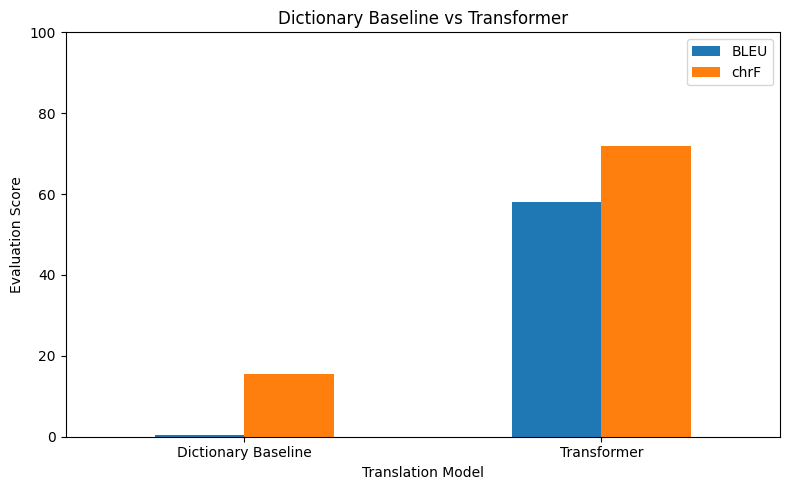

In [39]:

import matplotlib.pyplot as plt

results_df.plot(
    x="Model",
    y=["BLEU", "chrF"],
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Dictionary Baseline vs Transformer")
plt.xlabel("Translation Model")
plt.ylabel("Evaluation Score")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


In [40]:

from google.colab import files

evaluation_df[["en", "fr", "baseline_translation", "transformer_translation"]].to_csv(
    "translation_comparison.csv",
    index=False
)

results_df.to_csv(
    "metrics.csv",
    index=False
)

files.download("translation_comparison.csv")
files.download("metrics.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:

comparison_columns = [
    "en",
    "fr",
    "baseline_translation",
    "transformer_translation"
]

examples_df = evaluation_df[comparison_columns].sample(
    n=5,
    random_state=7
)

for _, row in examples_df.iterrows():
    print("English:", row["en"])
    print("Reference:", row["fr"])
    print("Baseline:", row["baseline_translation"])
    print("Transformer:", row["transformer_translation"])
    print("-" * 60)


English: You can't keep doing this, Tom.
Reference: Tu ne peux pas continuer comme ça, Tom.
Baseline: You can ' t keep doing this, tom.
Transformer: Tu ne peux pas continuer à faire ça, Tom.
------------------------------------------------------------
English: He has short hair.
Reference: Il a les cheveux courts.
Baseline: He has short hair.
Transformer: Il a des cheveux courts.
------------------------------------------------------------
English: French isn't my native language.
Reference: Le français n'est pas ma langue maternelle.
Baseline: French isn ' t my native language.
Transformer: Le français n'est pas ma langue maternelle.
------------------------------------------------------------
English: Don't try to talk right now.
Reference: N'essayez pas de parler tout de suite !
Baseline: Don ' t try to talk right now.
Transformer: N'essayez pas de parler maintenant.
------------------------------------------------------------
English: I've just talked to Tom about that matter.
Refe

In [42]:

english_sentence = input("Enter an English sentence: ")

french_translation = transformer_translate([english_sentence])[0]

print("English:", english_sentence)
print("French:", french_translation)


Enter an English sentence: I want to learn French.


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English: I want to learn French.
French: Je veux apprendre le français.
